In [2]:
!pip -q install xgboost shap


In [3]:
import io, json, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
import joblib

SEED = 42


In [5]:
import pandas as pd
import urllib.request
import io
import zipfile

# First, try downloading the dataset ZIP
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

try:
    response = urllib.request.urlopen(url, timeout=30)
    zfile = zipfile.ZipFile(io.BytesIO(response.read()))

    print("Files available in ZIP:")
    print(zfile.namelist())

    csv_name = next(
        name for name in zfile.namelist()
        if name.lower().endswith("student-mat.csv")
    )

    with zfile.open(csv_name) as file:
        df = pd.read_csv(file, sep=";")

except Exception as e:
    print("ZIP download failed:", e)
    print("Trying direct CSV download...")

    csv_url = (
        "https://archive.ics.uci.edu/"
        "ml/machine-learning-databases/00320/student-mat.csv"
    )

    df = pd.read_csv(csv_url, sep=";")

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print(df.dtypes)

Files available in ZIP:
['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']
Dataset downloaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


Missing values by column:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Duplicate rows: 0
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


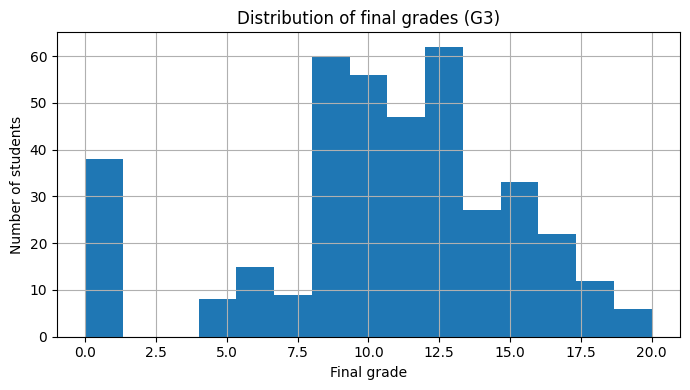

Risk class counts (0 = G3 >= 10, 1 = G3 < 10):


,count
at_risk,
0,265
1,130


Risk rate: 0.329


In [6]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10))
print("Duplicate rows:", df.duplicated().sum())
print(df["G3"].describe())

plt.figure(figsize=(7, 4))
df["G3"].hist(bins=15)
plt.title("Distribution of final grades (G3)")
plt.xlabel("Final grade")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

FEATURES = ["age", "studytime", "failures", "absences", "G1"]
data = df[FEATURES + ["G3"]].copy()
data["at_risk"] = (data["G3"] < 10).astype(int)

print("Risk class counts (0 = G3 >= 10, 1 = G3 < 10):")
display(data["at_risk"].value_counts().rename("count"))
print("Risk rate:", round(data["at_risk"].mean(), 3))


,accuracy,precision,recall,f1,roc_auc
0,0.835,0.741,0.769,0.755,0.962


              precision    recall  f1-score   support

 Not at risk       0.88      0.87      0.88        53
     At risk       0.74      0.77      0.75        26

    accuracy                           0.84        79
   macro avg       0.81      0.82      0.82        79
weighted avg       0.84      0.84      0.84        79



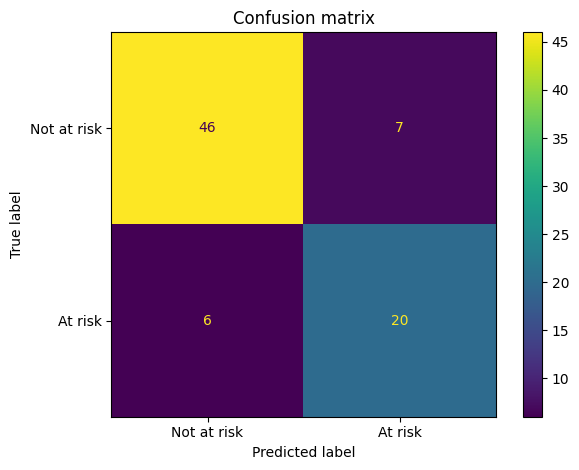

In [7]:
X = data[FEATURES].copy()
y = data["at_risk"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

model = XGBClassifier(
    n_estimators=250,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1
)
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred, zero_division=0),
    "recall": recall_score(y_test, pred, zero_division=0),
    "f1": f1_score(y_test, pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, proba),
}
display(pd.DataFrame([metrics]).round(3))
print(classification_report(y_test, pred, target_names=["Not at risk", "At risk"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Not at risk", "At risk"], values_format="d"
)
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()


,feature,mean_abs_shap
4,G1,2.5815
3,absences,0.5975
0,age,0.2802
2,failures,0.1676
1,studytime,0.1634


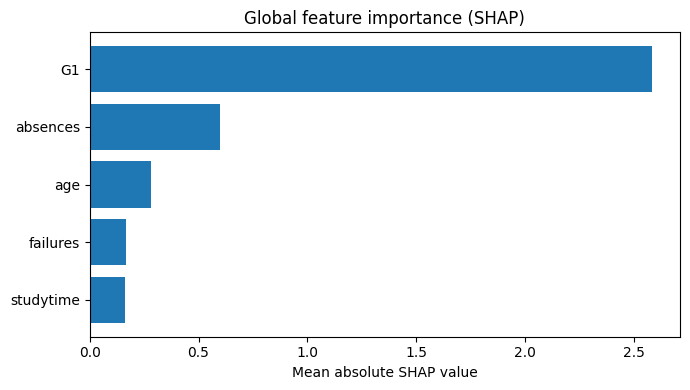

Example input:


,age,studytime,failures,absences,G1
383,19,1,1,0,6


Predicted risk probability: 0.99
Waterfall plot unavailable in this SHAP version: [08:30:28] /__w/xgboost/xgboost/src/c_api/c_api_utils.h:127: Check failed: std::accumulate(shape.cbegin(), shape.cend(), static_cast<bst_ulong>(1), std::multiplies<>{}) == chunksize * rows (10 vs. 30) : 
Stack trace:
  [bt] (0) /usr/local/lib/python3.13/dist-packages/xgboost/lib/libxgboost.so(+0x21ec5c) [0x7ccec601ec5c]
  [bt] (1) /usr/local/lib/python3.13/dist-packages/xgboost/lib/libxgboost.so(+0x229547) [0x7ccec6029547]
  [bt] (2) /usr/local/lib/python3.13/dist-packages/xgboost/lib/libxgboost.so(XGBoosterPredictFromDMatrix+0x434) [0x7ccec5f2f594]
  [bt] (3) /lib/x86_64-linux-gnu/libffi.so.8(+0x7b16) [0x7ccf07fe7b16]
  [bt] (4) /lib/x86_64-linux-gnu/libffi.so.8(+0x43ef) [0x7ccf07fe43ef]
  [bt] (5) /lib/x86_64-linux-gnu/libffi.so.8(ffi_call+0x12e) [0x7ccf07fe70be]
  [bt] (6) /usr/lib/python3.13/lib-dynload/_ctypes.cpython-313-x86_64-linux-gnu.so(+0x16da6) [0x7ccf07f9fda6]
  [bt] (7) /usr/lib/python3.13/l

In [8]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Global feature importance based on mean absolute SHAP value
sv = np.asarray(shap_values)
if sv.ndim == 3:
    sv = sv[:, :, -1]
global_importance = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": np.abs(sv).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(global_importance.round(4))

plt.figure(figsize=(7, 4))
plt.barh(global_importance["feature"][::-1], global_importance["mean_abs_shap"][::-1])
plt.xlabel("Mean absolute SHAP value")
plt.title("Global feature importance (SHAP)")
plt.tight_layout()
plt.show()

sample = X_test.iloc[[0]]
print("Example input:")
display(sample)
print("Predicted risk probability:", round(float(model.predict_proba(sample)[0, 1]), 3))

try:
    shap.plots.waterfall(explainer(X_test.iloc[0]), max_display=5)
except Exception as e:
    print("Waterfall plot unavailable in this SHAP version:", e)


In [9]:
joblib.dump(model, "model.joblib")
model_info = {
    "features": FEATURES,
    "target_definition": "at_risk = 1 when final grade G3 < 10 out of 20; 0 otherwise",
    "dataset": "UCI Student Performance, Mathematics subject",
    "threshold": 0.5,
    "metrics": {k: float(v) for k, v in metrics.items()}
}
with open("model_info.json", "w", encoding="utf-8") as f:
    json.dump(model_info, f, indent=2)

print("Saved model.joblib and model_info.json")
from google.colab import files
files.download("model.joblib")
files.download("model_info.json")


Saved model.joblib and model_info.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>